# Five-layer, 512-unit GRU: a separate 15-sign experiment

This notebook implements and trains a separate model from scratch using the same 15-class signer-disjoint ASL Citizen cache, temporal/spatial augmentation, 23 geometry features, regularization, selection policy and frozen-backbone logistic readout as the earlier 2-layer 256-unit trajectory model. Only the recurrent layer count and hidden size are deliberately changed. Training is CUDA-only. The same validation set informed earlier development; the existing official test set has also been examined before, so its result is not an untouched independent estimate. Run all cells to train; reruns refuse to overwrite existing artifacts.

Pipeline: precomputed MediaPipe landmarks → normalization already in cache → GRU → temporal mean pooling + geometry → linear classifier. Stage two freezes the selected GRU and refits the classifier with train-only logistic regression. No camera or landmark extraction is needed.

In [1]:
from pathlib import Path
import sys, json, time, random, hashlib, warnings, copy
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/sign_language').is_dir())
sys.path.insert(0,str(ROOT/'src'))
from sign_language.training import LandmarkDataset, backward_step, cuda_check
from sign_language.temporal_augmentation import TemporalCollator, CONFIG as TEMPORAL_CONFIG
from sign_language.regularization import augment_batch, PROFILES
from sign_language.trajectory_geometry import trajectory_batch, fit_statistics, FEATURES
from sign_language.five_sign_pilot import POLICY, early_stop_reason, select_epoch, sha256
from sign_language.expanded_pilot import SIGNS, verify_parent_chunks
CACHE=ROOT/'data/training/asl-fifteen-signs-128-v1'
PARENT=ROOT/'data/training/asl-gru-128-v1'
OUT=ROOT/'models/asl-gru-fifteen-signs-5layer-512-v1'
BASE=ROOT/'models/asl-gru-fifteen-signs-trajectory-readout-c01'
manifest=json.loads((CACHE/'manifest.json').read_text())
assert list(manifest['labels'])==list(SIGNS)
for name,digest in manifest['files_sha256'].items():
    assert sha256(CACHE/name)==digest, name
verify_parent_chunks(PARENT,manifest)
base_config=json.loads((BASE/'config.json').read_text())
base_hash=sha256(BASE/'best.pt')
assert not OUT.exists(), f'{OUT} exists; choose a new version to avoid overwriting'
assert torch.cuda.is_available(), 'CUDA is required for this experiment'
torch.set_num_threads(2)
torch.backends.cudnn.enabled=False
torch.backends.cudnn.benchmark=False
random.seed(42);np.random.seed(42);torch.manual_seed(42);torch.cuda.manual_seed_all(42)
print('GPU:', cuda_check())
print('Labels:',list(SIGNS),'cache:',manifest['cache_id'])
print('Train/validation:',*[len(LandmarkDataset(CACHE,s)) for s in ('train','val')])

GPU: {'torch': '2.11.0+cu128', 'cuda_runtime': '12.8', 'gpu': 'NVIDIA GeForce RTX 4060', 'vram_bytes': 8585216000}
Labels: ['HELLO', 'NO', 'PLEASE', 'THANKYOU', 'YES', 'ME', 'YOU', 'WE', 'MY', 'YOUR', 'OUR', 'HELP', 'GOOD', 'NEED', 'LOVE'] cache: 63aa81227c6fef495bba0a25cc670871c3a570fa3cb3ba95b2bcf259c5dacbf4
Train/validation: 219 60


## Model definition

The network explicitly defines the five-layer GRU, valid-frame mean pooling, geometry standardization and 15-output classifier. It uses 254 values per frame and 23 train-standardized geometry values.

In [2]:
class DeepTrajectoryGRU(nn.Module):
    def __init__(self, input_size=254, hidden_size=512, layers=5, classes=15, dropout=.5):
        super().__init__()
        self.gru=nn.GRU(input_size,hidden_size,num_layers=layers,batch_first=True,dropout=dropout)
        self.dropout=nn.Dropout(dropout)
        self.classifier=nn.Linear(hidden_size+len(FEATURES),classes)
        for name in ('median','mean','scale'):
            self.register_buffer('geometry_'+name,torch.ones(len(FEATURES)) if name=='scale' else torch.zeros(len(FEATURES)))
    def set_statistics(self,stats):
        for name in ('median','mean','scale'):
            value=torch.tensor(stats[name],dtype=torch.float32,device=self.geometry_mean.device)
            assert value.shape==(len(FEATURES),) and torch.isfinite(value).all()
            if name=='scale': assert (value>0).all()
            getattr(self,'geometry_'+name).copy_(value)
    def encode(self,frames,lengths):
        packed=pack_padded_sequence(frames,lengths.cpu(),batch_first=True,enforce_sorted=False)
        packed,_=self.gru(packed)
        values,actual=pad_packed_sequence(packed,batch_first=True)
        mask=(torch.arange(values.shape[1],device=values.device)[None,:]<actual.to(values.device)[:,None]).unsqueeze(-1)
        return (values*mask).sum(1)/actual.to(values.device).clamp_min(1)[:,None]
    def standardized_geometry(self,geometry):
        return (torch.where(torch.isnan(geometry),self.geometry_median,geometry)-self.geometry_mean)/self.geometry_scale
    def forward(self,frames,lengths):
        pooled=self.dropout(self.encode(frames,lengths))
        geometry=torch.as_tensor(trajectory_batch(frames,lengths),device=frames.device,dtype=torch.float32)
        values=torch.cat((pooled,self.standardized_geometry(geometry)),dim=1)
        return self.classifier(values)

model=DeepTrajectoryGRU().cuda()
print(model)
print('Trainable parameters:',sum(p.numel() for p in model.parameters()))
assert model.gru.num_layers==5 and model.gru.hidden_size==512 and model.classifier.in_features==535

DeepTrajectoryGRU(
  (gru): GRU(254, 512, num_layers=5, batch_first=True, dropout=0.5)
  (dropout): Dropout(p=0.5, inplace=False)
  (classifier): Linear(in_features=535, out_features=15, bias=True)
)
Trainable parameters: 7491432


## Data and geometry statistics

All geometry standardization is fitted on the original training split only. The loaders use the existing ordered temporal augmentation followed by spatial perturbations on training batches. Validation uses original features.

In [3]:
train_data=LandmarkDataset(CACHE,'train'); val_data=LandmarkDataset(CACHE,'val')
clean_loader=DataLoader(train_data,batch_size=16,shuffle=False,num_workers=0)
val_loader=DataLoader(val_data,batch_size=16,shuffle=False,num_workers=0)
generator=torch.Generator().manual_seed(42)
# Windows notebook cells cannot reliably spawn notebook-defined processes; using zero loader workers changes throughput, not the samples or augmentation policy.
train_loader=DataLoader(train_data,batch_size=4,shuffle=True,num_workers=0,generator=generator,collate_fn=TemporalCollator(enabled=True))
training_geometry=np.concatenate([trajectory_batch(x,l) for x,l,_ in clean_loader])
stats=fit_statistics(training_geometry);model.set_statistics(stats)
print('Geometry shape:',training_geometry.shape,'missing values:',int(np.isnan(training_geometry).sum()))

Geometry shape: (219, 23) missing values: 114


## Stage one: train the GRU and classifier

AdamW, cross entropy, dropout, gradient clipping, AMP, 28-epoch cap and early-stopping rules match the previous experiment. The chosen checkpoint uses the same validation competitiveness and train/validation gap rule. Only temporary candidate states are held in memory; the separate final checkpoint is saved after fitting the readout.

In [4]:
def run_epoch(loader, training=False):
    model.train(training)
    loss_sum=0.; total=0; correct=0; top5=0; matrix=np.zeros((15,15),dtype=np.int64)
    started=time.monotonic(); skipped=0
    with torch.set_grad_enabled(training):
        for frames,lengths,targets in loader:
            frames,targets=frames.cuda(),targets.cuda()
            if training:
                frames=augment_batch(frames)
                optimizer.zero_grad(set_to_none=True)
            with torch.autocast('cuda',dtype=torch.float16):
                logits=model(frames,lengths);loss=nn.functional.cross_entropy(logits,targets)
            if not torch.isfinite(loss): raise FloatingPointError('Non-finite loss')
            if training: skipped+=int(not backward_step(model,optimizer,loss,scaler))
            count=len(targets);total+=count;loss_sum+=loss.item()*count
            correct+=(logits.argmax(1)==targets).sum().item()
            top5+=(logits.topk(5,dim=1).indices==targets[:,None]).any(1).sum().item()
            matrix+=np.bincount((targets*15+logits.argmax(1)).cpu().numpy(),minlength=225).reshape(15,15)
    tp=np.diag(matrix).astype(float); support=matrix.sum(1);pred=matrix.sum(0)
    precision=np.divide(tp,pred,out=np.zeros(15),where=pred>0);recall=np.divide(tp,support,out=np.zeros(15),where=support>0)
    f1=np.divide(2*precision*recall,precision+recall,out=np.zeros(15),where=precision+recall>0)
    return {'loss':loss_sum/total,'top1':correct/total,'top5':top5/total,'samples':total,'macro_precision':float(precision.mean()),'macro_recall':float(recall.mean()),'macro_f1':float(f1.mean()),'weighted_f1':float((f1*support).sum()/support.sum()),'class_correct':tp.astype(int).tolist(),'seconds':time.monotonic()-started,'skipped_amp_updates':skipped}

optimizer=torch.optim.AdamW(model.parameters(),lr=.001,weight_decay=.001)
scaler=torch.amp.GradScaler('cuda')
records=[];states={};best_loss=float('inf');best_acc=-1.;loss_stale=acc_stale=0;stop='epoch_cap'
OUT.mkdir(parents=True,exist_ok=False)
(OUT/'status.json').write_text(json.dumps({'status':'training','epoch':0},indent=2))
for epoch in range(1,29):
    train=run_epoch(train_loader,True);clean=run_epoch(clean_loader);val=run_epoch(val_loader)
    row={'epoch':epoch,'train':train,'train_clean':clean,'val':val,'accuracy_gap':clean['top1']-val['top1'],'loss_gap':val['loss']-clean['loss']}
    records.append(row);states[epoch]={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    (OUT/'history.json').write_text(json.dumps(records,indent=2))
    (OUT/'status.json').write_text(json.dumps({'status':'training','epoch':epoch},indent=2))
    if val['loss']<best_loss-POLICY['loss_min_delta']:
        best_loss=val['loss'];loss_stale=0
    else: loss_stale+=1
    acc_stale=0 if val['top1']>best_acc+1e-12 else acc_stale+1
    best_acc=max(best_acc,val['top1'])
    print(f"Epoch {epoch:02}: train {clean['top1']:.1%}, validation {val['top1']:.1%}, validation loss {val['loss']:.4f}",flush=True)
    reason=early_stop_reason(records,loss_stale,acc_stale)
    if reason: stop=reason;break
normal_choice,normal_selection=select_epoch(records)
please_index=list(SIGNS).index('PLEASE');my_index=list(SIGNS).index('MY')
eligible=[r for r in records if r['val']['class_correct'][please_index]==4 and r['val']['class_correct'][my_index]==4 and r['val']['top1']*r['val']['samples']>=50]
chosen,selection=select_epoch(eligible if eligible else records)
selection['target_qualified_epochs']=[r['epoch'] for r in eligible]
selection['fallback_to_normal_selection']=not bool(eligible)
selection['normal_selected_epoch']=normal_choice['epoch']
model.load_state_dict(states[chosen['epoch']]);del states
torch.save({'model':model.state_dict(),'chosen':chosen,'selection':selection,'records':records},OUT/'recovery-backbone.pt')
print('Selected epoch:',chosen['epoch'],'stop:',stop,'selection:',selection)

Epoch 01: train 23.3%, validation 25.0%, validation loss 2.2236
Epoch 02: train 33.8%, validation 30.0%, validation loss 2.0221
Epoch 03: train 47.5%, validation 40.0%, validation loss 1.7874
Epoch 04: train 43.4%, validation 35.0%, validation loss 1.7285
Epoch 05: train 63.0%, validation 51.7%, validation loss 1.3544
Epoch 06: train 59.8%, validation 51.7%, validation loss 1.3781
Epoch 07: train 63.9%, validation 58.3%, validation loss 1.3186
Epoch 08: train 57.1%, validation 58.3%, validation loss 1.3825
Epoch 09: train 67.6%, validation 63.3%, validation loss 1.1700
Epoch 10: train 68.9%, validation 63.3%, validation loss 1.0392
Epoch 11: train 62.6%, validation 63.3%, validation loss 1.3692
Epoch 12: train 71.2%, validation 61.7%, validation loss 1.1185
Epoch 13: train 64.8%, validation 55.0%, validation loss 1.2742
Selected epoch: 10 stop: validation_loss_patience selection: {'policy': {'accuracy_tolerance': 'one validation example below best observed top-1', 'loss_tolerance': 0.1

## Stage two: freeze the recurrent backbone and fit the linear readout

Fit L2 multinomial logistic regression with C=0.1 on the original training clips, as in the previous trajectory readout. Hidden outputs are unscaled; the 23 geometry values use training-only statistics. The linear weights are copied into the model.

In [5]:
def collect(loader):
    model.eval(); hidden=[]; geometry=[]; targets=[]
    with torch.inference_mode():
        for frames,lengths,y in loader:
            frames=frames.cuda()
            with torch.autocast('cuda',dtype=torch.float16): h=model.encode(frames,lengths)
            hidden.append(h.float().cpu().numpy());geometry.append(trajectory_batch(frames,lengths));targets.extend(y.tolist())
    return np.concatenate(hidden),np.concatenate(geometry),np.asarray(targets)
train_hidden,train_geometry,train_targets=collect(clean_loader)
train_z=model.standardized_geometry(torch.from_numpy(train_geometry).cuda()).cpu().numpy()
with warnings.catch_warnings():
    warnings.simplefilter('error',ConvergenceWarning)
    head=LogisticRegression(C=.1,solver='lbfgs',max_iter=2000,random_state=42).fit(np.concatenate([train_hidden,train_z],axis=1),train_targets)
assert np.array_equal(head.classes_,np.arange(15))
with torch.no_grad():
    model.classifier.weight.copy_(torch.from_numpy(head.coef_).float().cuda())
    model.classifier.bias.copy_(torch.from_numpy(head.intercept_).float().cuda())
model.gru.requires_grad_(False)
torch.save({'model':model.state_dict(),'chosen':chosen,'selection':selection,'records':records,'stats':stats},OUT/'recovery-readout.pt')
print('Classifier iterations:',head.n_iter_,'backbone frozen:',not any(p.requires_grad for p in model.gru.parameters()))

Classifier iterations: [174] backbone frozen: True


## Final evaluation and saved model

Report train, official validation and previously inspected official test results. This test set was already used during development, and its 182 examples cover only the selected 15 labels. Webcam reliability remains a separate question.

In [6]:
def final_metrics(split):
    if split=='test':
        from sign_language.small_vocab_benchmark import select_test_subset
        from torch.utils.data import TensorDataset
        parent_manifest=json.loads((PARENT/'manifest.json').read_text())
        index=json.loads((PARENT/'test-index.json').read_text())
        arrays=[np.load(PARENT/f'test-{name}.npy',mmap_mode='r') for name in ('features','lengths','targets')]
        rows,x,n,y=select_test_subset(index,*arrays,manifest['labels'],parent_manifest['labels'])
        assert not ({r['participant_id'] for r in rows}&set(manifest['participants']['train']+manifest['participants']['val']))
        dataset=TensorDataset(torch.from_numpy(x),torch.from_numpy(n),torch.from_numpy(y))
    else: dataset=LandmarkDataset(CACHE,split)
    loader=DataLoader(dataset,batch_size=16,shuffle=False,num_workers=0)
    h,g,y=collect(loader)
    z=model.standardized_geometry(torch.from_numpy(g).cuda()).detach().cpu().numpy()
    # Reference inference uses a float32 linear head after CUDA mixed-precision GRU.
    with torch.no_grad():
        logits=nn.functional.linear(torch.from_numpy(np.concatenate([h,z],axis=1)).float(),model.classifier.weight.cpu(),model.classifier.bias.cpu())
    prob=logits.softmax(1);pred=prob.argmax(1).numpy();loss=nn.functional.cross_entropy(logits,torch.from_numpy(y).long()).item()
    precision,recall,f1,support=precision_recall_fscore_support(y,pred,labels=np.arange(15),zero_division=0)
    return {'samples':len(y),'correct':int((pred==y).sum()),'top1':float((pred==y).mean()),'top5':float((prob.topk(5,dim=1).indices.numpy()==y[:,None]).any(1).mean()),'loss':loss,'macro_precision':float(precision.mean()),'macro_recall':float(recall.mean()),'macro_f1':float(f1.mean()),'weighted_f1':float(np.average(f1,weights=support)),'confusion':confusion_matrix(y,pred,labels=np.arange(15)).tolist(),'per_class':{name:{'support':int(support[i]),'precision':float(precision[i]),'recall':float(recall[i]),'f1':float(f1[i])} for i,name in enumerate(SIGNS)}}
results={s:final_metrics(s) for s in ('train','val','test')}
config={'architecture':'notebook-deep-gru-trajectory-v1','model':{'input_size':254,'hidden_size':512,'layers':5,'classes':15,'dropout':.5},'preprocessing':base_config['preprocessing'],'cache_id':manifest['cache_id'],'geometry_features':list(FEATURES),'geometry_statistics':stats,'seed':42,'batch_size':4,'loader_workers':0,'optimizer':'AdamW','learning_rate':.001,'weight_decay':.001,'epochs_cap':28,'selection':POLICY,'temporal_augmentation':TEMPORAL_CONFIG,'regularization':PROFILES['regularized-v1'],'stage_two':'L2 logistic regression, C=0.1, lbfgs, max_iter=2000, frozen GRU','test_previously_seen':True,'implementation_notebook':'notebooks/04_deep_gru_5layer_512.ipynb'}
checkpoint={'config':config,'model':{k:v.detach().cpu() for k,v in model.state_dict().items()},'labels':manifest['labels'],'epoch':chosen['epoch']}
torch.save(checkpoint,OUT/'model.pt')
(OUT/'config.json').write_text(json.dumps(config,indent=2));(OUT/'labels.json').write_text(json.dumps(manifest['labels'],indent=2))
report={'status':'complete','selection':selection,'stop_reason':stop,'epochs':len(records),'parameters':sum(p.numel() for p in model.parameters()),'checkpoint_sha256':sha256(OUT/'model.pt'),'baseline_sha256':base_hash,'baseline_unchanged':sha256(BASE/'best.pt')==base_hash,'metrics':results,'history':records}
assert report['baseline_unchanged']
(OUT/'report.json').write_text(json.dumps(report,indent=2));(OUT/'status.json').write_text(json.dumps({'status':'complete','selected_epoch':chosen['epoch']},indent=2))
for name in ('recovery-backbone.pt','recovery-readout.pt'): (OUT/name).unlink(missing_ok=True)
for split,m in results.items(): print(f"{split}: top-1={m['top1']:.2%}, top-5={m['top5']:.2%}, loss={m['loss']:.4f}, macro F1={m['macro_f1']:.4f}, n={m['samples']}")
print('Separate checkpoint:',OUT/'model.pt')

train: top-1=90.87%, top-5=99.54%, loss=0.4643, macro F1=0.9108, n=219
val: top-1=85.00%, top-5=100.00%, loss=0.6621, macro F1=0.8385, n=60
test: top-1=75.82%, top-5=98.90%, loss=0.7797, macro F1=0.7583, n=182
Separate checkpoint: E:\minor_major_proj\models\asl-gru-fifteen-signs-5layer-512-v1\model.pt


## Learning curves and per-class results

Clean training metrics and validation metrics are calculated after each epoch. The final confusion matrix and per-class F1 refer to the fitted stage-two classifier on the previously inspected test split.

HELLO        n=14 precision=0.917 recall=0.786 F1=0.846
NO           n=11 precision=0.900 recall=0.818 F1=0.857
PLEASE       n=13 precision=0.833 recall=0.769 F1=0.800
THANKYOU     n=12 precision=0.462 recall=0.500 F1=0.480
YES          n=10 precision=0.750 recall=0.900 F1=0.818
ME           n=13 precision=1.000 recall=0.923 F1=0.960
YOU          n=12 precision=0.636 recall=0.583 F1=0.609
WE           n=12 precision=0.846 recall=0.917 F1=0.880
MY           n=13 precision=0.647 recall=0.846 F1=0.733
YOUR         n=11 precision=0.818 recall=0.818 F1=0.818
OUR          n=12 precision=0.786 recall=0.917 F1=0.846
HELP         n=13 precision=1.000 recall=0.615 F1=0.762
GOOD         n=12 precision=0.556 recall=0.417 F1=0.476
NEED         n=12 precision=0.500 recall=0.667 F1=0.571
LOVE         n=12 precision=0.917 recall=0.917 F1=0.917


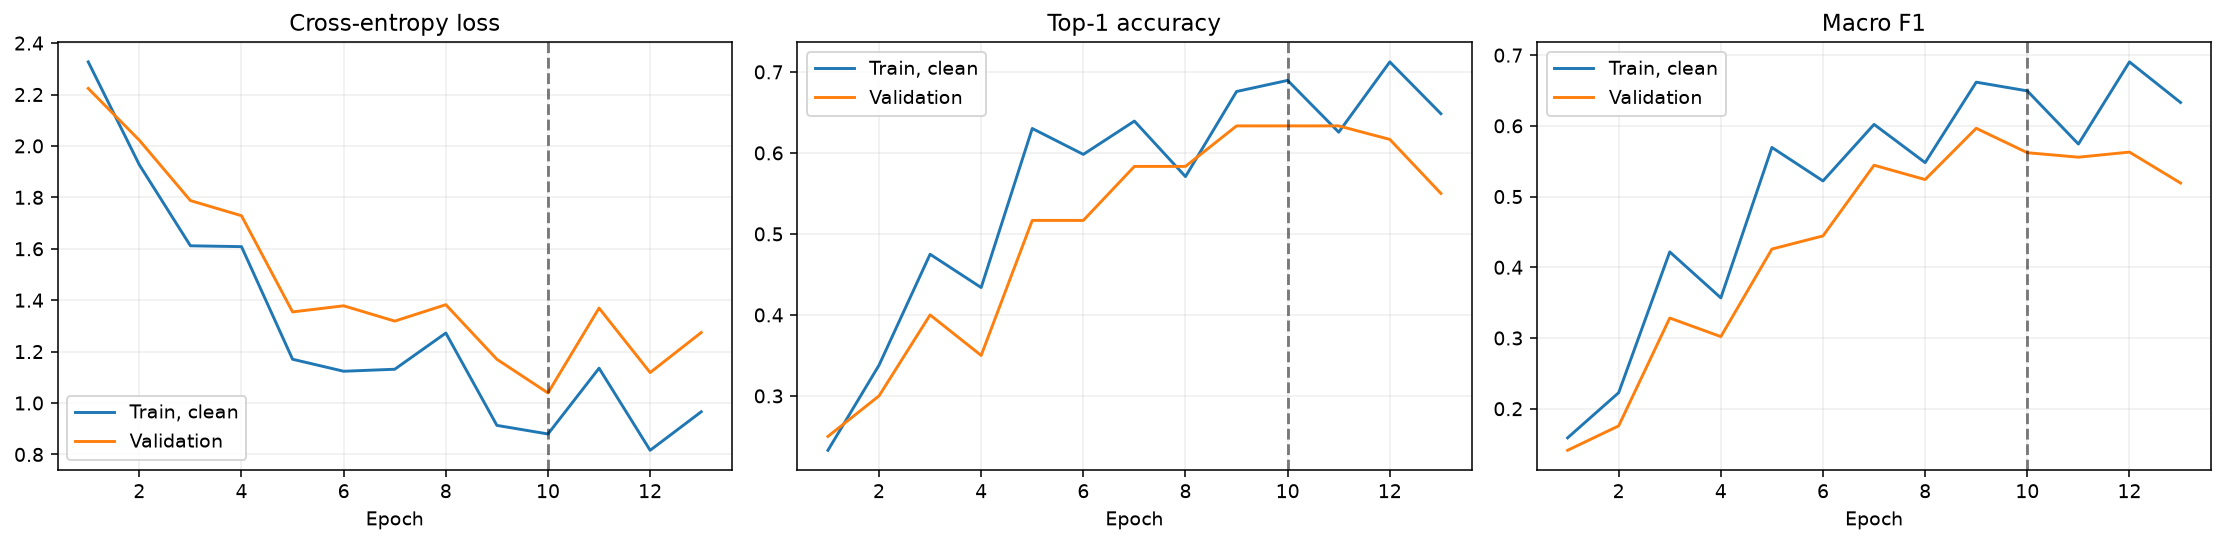

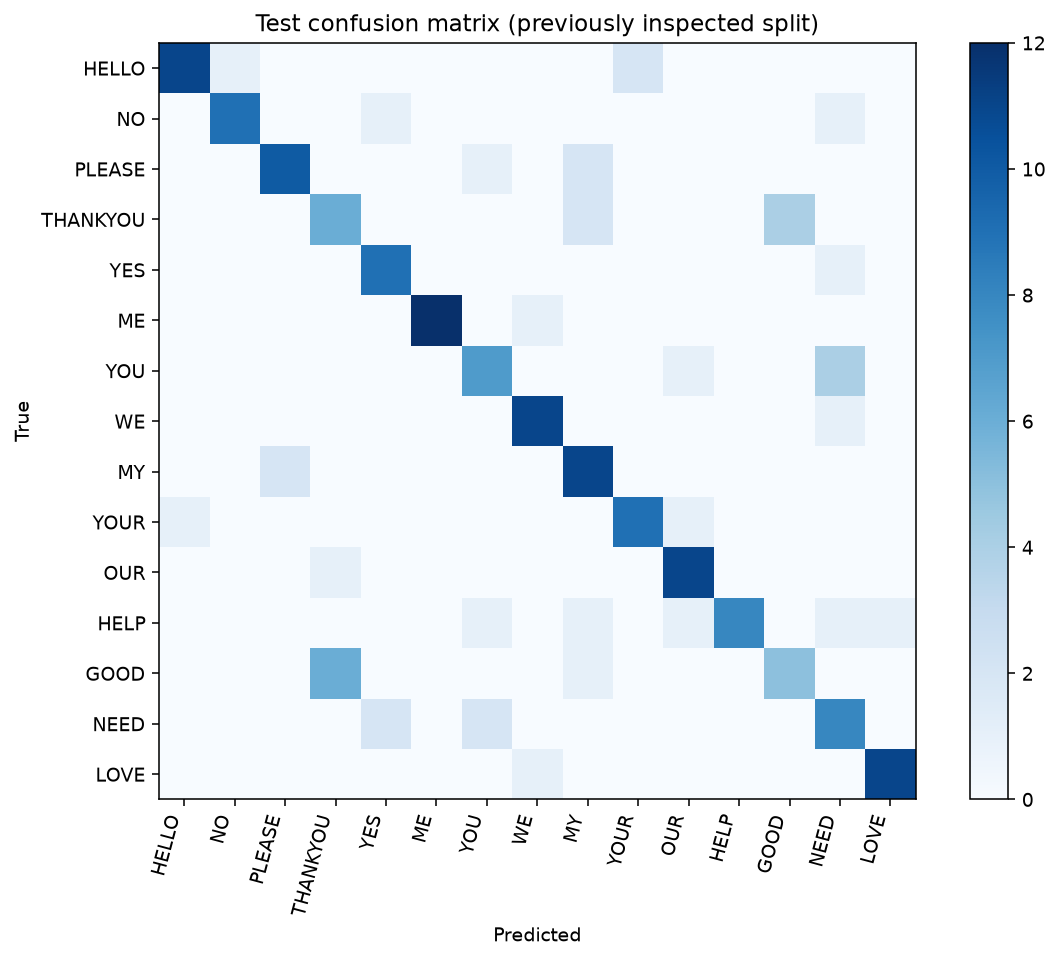

In [7]:
epochs=[r['epoch'] for r in records]
fig,ax=plt.subplots(1,3,figsize=(16,4))
for key,label in [('train_clean','Train, clean'),('val','Validation')]:
    ax[0].plot(epochs,[r[key]['loss'] for r in records],label=label)
    ax[1].plot(epochs,[r[key]['top1'] for r in records],label=label)
    ax[2].plot(epochs,[r[key]['macro_f1'] for r in records],label=label)
for a,title in zip(ax,['Cross-entropy loss','Top-1 accuracy','Macro F1']):
    a.set(title=title,xlabel='Epoch');a.axvline(chosen['epoch'],color='black',linestyle='--',alpha=.5);a.legend();a.grid(alpha=.2)
plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(9,7));cm=np.array(results['test']['confusion']);im=ax.imshow(cm,cmap='Blues')
ax.set(xticks=range(15),yticks=range(15),xticklabels=SIGNS,yticklabels=SIGNS,xlabel='Predicted',ylabel='True',title='Test confusion matrix (previously inspected split)')
plt.setp(ax.get_xticklabels(),rotation=75,ha='right');fig.colorbar(im,ax=ax);plt.tight_layout();plt.show()
for label,info in results['test']['per_class'].items(): print(f"{label:12s} n={info['support']:2d} precision={info['precision']:.3f} recall={info['recall']:.3f} F1={info['f1']:.3f}")